# Caching Matrix Factorizations

The message passing rules of RxInfer are written for matrices they receive as arguments: a rule that needs the inverse of a covariance computes it, and the next rule that needs the same inverse computes it again. In two common situations that repetition is most of the run time. A constant matrix passed into the model, such as a dense sensor-noise covariance, is factorized at every node that touches it. A posterior shared by many nodes, such as the weights of a regression, is formed once per iteration and then inverted by every node that reads it.

[`BayesBase.MatrixWithCachedInverse`](https://reactivebayes.github.io/BayesBase.jl/stable/#BayesBase.MatrixWithCachedInverse) removes the repetition from the user's side. This example explains what the cache is, then shows the two ways to put it where the rules will find it: as a constant the model takes, and, through a form constraint, inside a posterior the engine forms. Both leave the model, the rules and the `infer` call unchanged, and both are measured.

In [18]:
using RxInfer, BayesBase, LinearAlgebra, StableRNGs, BenchmarkTools, Plots

## What the cache is

`MatrixWithCachedInverse(A)` wraps a copy of a symmetric positive-definite matrix. It is an ordinary `AbstractMatrix`: it multiplies, adds and indexes like its parent. What it adds is memory. The first `cholesky`, `\`, `logdet` or `inv` on it computes the result and stores it; every later request returns the stored result. `inv` returns another wrapper, linked back to the original, so `inv(inv(A))` is `A` itself and a rule that goes from a covariance to a precision and back pays nothing the second time. With FastCholesky loaded, which RxInfer does, the `fastcholesky` and `cholinv` calls that the rules use read the same cache.

Two rules of use. The input must be exactly symmetric, so pass a matrix that comes out of `inv` or a product as `Symmetric(M)`. And the cache is never invalidated: the wrapper owns its copy, and mutating the original afterwards has no effect on it.

In [19]:
A = let G = randn(StableRNG(1), 64, 64); Matrix(Symmetric(G * G' ./ 64 + I)) end
A_cached = MatrixWithCachedInverse(A)

@btime cholesky($A);           # the plain matrix: a factorization every time
@btime cholesky($A_cached);    # the wrapper: a factorization the first time, a lookup after
println("inv(inv(A)) === A: ", inv(inv(A_cached)) === A_cached)

  11.291 μs (3 allocations: 32.08 KiB)
  52.558 ns (0 allocations: 0 bytes)
inv(inv(A)) === A: true


## A constant matrix: the sensor-noise covariance of a wide-sensor smoother

A sensor array watches $d$ hidden states through $m \gg d$ sensors with correlated noise:

$$\begin{aligned}
x_t &\sim \mathcal{N}(A x_{t-1}, Q), \\
y_t &\sim \mathcal{N}(B x_t, R),
\end{aligned}$$

with $B$ the $m \times d$ sensor geometry and $R$ the dense $m \times m$ noise covariance. The smoother is the usual chain in covariance form, with the noise matrices passed in as constants.

In [20]:
@model function sensor_array(y, x0, A, B, Q, R)
    x_prior ~ x0
    x_prev = x_prior
    for t in eachindex(y)
        x[t] ~ MvNormalMeanCovariance(A * x_prev, Q)
        y[t] ~ MvNormalMeanCovariance(B * x[t], R)
        x_prev = x[t]
    end
end

function sensor_array_problem(d, m, n; rng = StableRNG(42))
    A = zeros(d, d)
    for (k, period) in zip(1:2:d, Iterators.cycle((70, 40)))   # block-diagonal rotations
        φ = 2π / period
        A[k:k+1, k:k+1] = [cos(φ) -sin(φ); sin(φ) cos(φ)]
    end
    B = randn(rng, m, d) ./ sqrt(d)
    Q = 0.01 * diageye(d)
    G = randn(rng, m, m)
    R = Matrix(Symmetric(G * G' ./ m + I))                      # dense, correlated sensor noise
    x = Vector{Vector{Float64}}(undef, n)
    y = Vector{Vector{Float64}}(undef, n)
    previous = 3.0 .* ones(d)
    for t in 1:n
        x[t] = rand(rng, MvNormal(A * previous, Q))
        y[t] = rand(rng, MvNormal(B * x[t], R))
        previous = x[t]
    end
    return (; A, B, Q, R, x, y)
end

function smooth(problem, R)
    (; A, B, Q, y) = problem
    d = size(A, 1)
    return infer(
        model = sensor_array(x0 = MvNormalMeanCovariance(zeros(d), 10.0 * diageye(d)), A = A, B = B, Q = Q, R = R),
        data = (y = y,),
        options = (limit_stack_depth = 500,),
    )
end

d, m, n = 4, 128, 200
problem = sensor_array_problem(d, m, n)
result = smooth(problem, problem.R)
posterior = result.posteriors[:x];

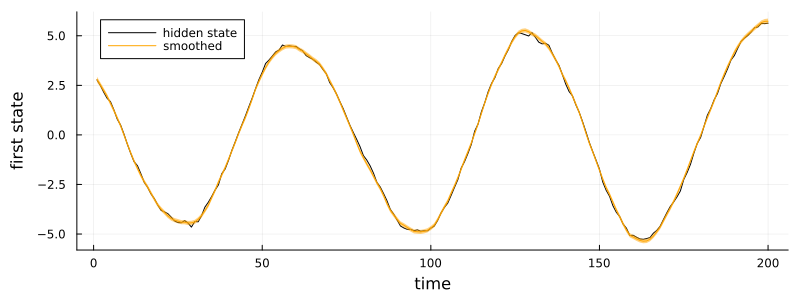

In [21]:
means = mean.(posterior)
stds = [sqrt.(diag(cov(q))) for q in posterior]
p = plot(getindex.(problem.x, 1), label = "hidden state", color = :black, xlabel = "time", ylabel = "first state")
plot!(p, getindex.(means, 1), ribbon = getindex.(stds, 1), label = "smoothed", color = :orange, size = (800, 300), bottom_margin = 5Plots.mm, left_margin = 5Plots.mm)

**Where the time goes.** The observation `y[t] ~ MvNormalMeanCovariance(B * x[t], R)` is two nodes: the Gaussian and the multiplication by $B$. The message from the Gaussian towards the product is $\mathcal{N}(y_t, R)$, with $R$ passed through as it is, and the multiplication node sends it backwards through $B$ by dividing $B^\top$ by the Cholesky factor of $R$. That is an $O(m^3)$ factorization at every one of the $n$ steps, of a matrix that never changes, while everything else in a step is $d \times d$ work or an $O(m^2 d)$ product. At 256 sensors it is more than half of the run.

**The fix.** Wrap $R$ before passing it in. The model and the `infer` call do not change.

In [22]:
R_cached = MatrixWithCachedInverse(problem.R)
result_cached = smooth(problem, R_cached)

largest_difference = maximum(zip(result.posteriors[:x], result_cached.posteriors[:x])) do (a, b)
    return max(maximum(abs, mean(a) - mean(b)), maximum(abs, cov(a) - cov(b)))
end

println("largest difference between the posteriors: ", largest_difference)

largest difference between the posteriors: 0.0


The sweep below smooths the same $n = 200$ steps with $d = 4$ states and $m$ from 16 to 256 sensors, with a plain `Matrix` and with the wrapper; the wrapper is built inside the timed call, so its one factorization is included.

In [23]:
sensor_counts = [16, 32, 64, 128, 256]
sensor_timings = map(sensor_counts) do m
    p = sensor_array_problem(d, m, n)
    plain = @benchmark smooth($p, $(p.R)) seconds = 2
    cached = @benchmark smooth($p, MatrixWithCachedInverse($(p.R))) seconds = 2
    return (m = m, plain = median(plain).time / 1e6, cached = median(cached).time / 1e6)
end

5-element Vector{@NamedTuple{m::Int64, plain::Float64, cached::Float64}}:
 (m = 16, plain = 23.762375, cached = 23.964084)
 (m = 32, plain = 26.412979, cached = 24.477396)
 (m = 64, plain = 27.185041, cached = 24.5764375)
 (m = 128, plain = 38.109084, cached = 26.414604)
 (m = 256, plain = 82.661375, cached = 33.6751875)

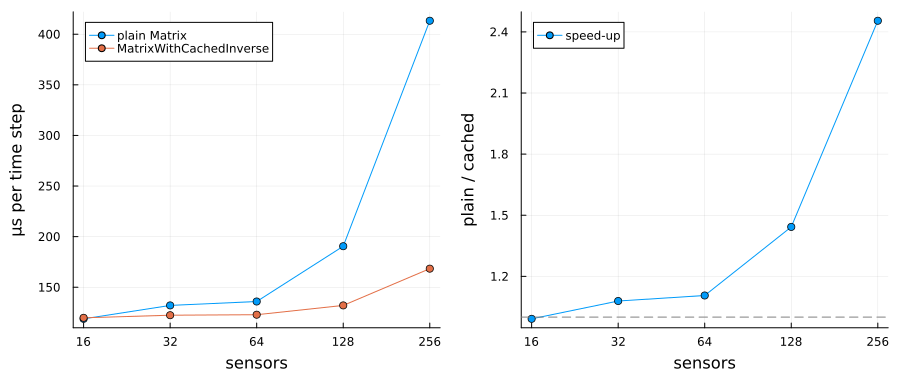

In [24]:
per_step = plot(sensor_counts, [t.plain / n * 1e3 for t in sensor_timings], marker = :circle, label = "plain Matrix", xscale = :log2, xticks = (sensor_counts, string.(sensor_counts)), xlabel = "sensors", ylabel = "μs per time step", legend = :topleft)
plot!(per_step, sensor_counts, [t.cached / n * 1e3 for t in sensor_timings], marker = :circle, label = "MatrixWithCachedInverse")
speedup = plot(sensor_counts, [t.plain / t.cached for t in sensor_timings], marker = :circle, label = "speed-up", xscale = :log2, xticks = (sensor_counts, string.(sensor_counts)), xlabel = "sensors", ylabel = "plain / cached", legend = :topleft)
hline!(speedup, [1.0], linestyle = :dash, color = :gray, label = nothing)
plot(per_step, speedup, layout = (1, 2), size = (900, 380), left_margin = 5Plots.mm, bottom_margin = 5Plots.mm)

With few sensors the two runs cost the same: a step of the engine, with its products and subscriptions, takes around a hundred microseconds whatever the matrices, and a small Cholesky is far below that. From about 64 sensors the factorization shows, and at 256 it dominates the plain run, which the wrapper makes two to three times faster. The same cache serves `free_energy = true`, where every observation node also needs `logdet(R)` and `inv(R)`.

## A shared posterior: the weights of a regression

In variational message passing a posterior that many nodes read is formed once per iteration and sent to all of them. Linear regression with the `softdot` node, $y_i \sim \mathcal{N}(\theta^\top x_i, \gamma^{-1})$, is the plain case: one weight vector $\theta$ and one node per sample. Here the inputs are measured with known correlated noise, so each $x_i$ is a latent variable centred on its measurement $\tilde{x}_i$ with precision $\Lambda_x$:

$$\begin{aligned}
\theta &\sim \mathcal{N}(0, I), \qquad \gamma \sim \Gamma(1, 1), \\
x_i &\sim \mathcal{N}(\tilde{x}_i, \Lambda_x^{-1}), \qquad y_i \sim \mathcal{N}(\theta^\top x_i, \gamma^{-1}).
\end{aligned}$$

In [25]:
@model function noisy_input_regression(y, x_measured, Λx, d)
    θ ~ MvNormalMeanCovariance(zeros(d), diageye(d))
    γ ~ GammaShapeRate(1.0, 1.0)
    for i in eachindex(y)
        x[i] ~ MvNormalMeanPrecision(x_measured[i], Λx)
        y[i] ~ softdot(θ, x[i], γ)
    end
end

constraints = @constraints begin
    q(θ, x, γ) = q(θ)q(x)q(γ)
end

function regression_problem(d, n; rng = StableRNG(d), input_noise = 0.05)
    θ = randn(rng, d)
    G = randn(rng, d, d)
    Σx = input_noise .* Matrix(Symmetric(G * G' ./ d + I))
    x_true = [randn(rng, d) for _ in 1:n]
    x_measured = [rand(rng, MvNormal(x, Σx)) for x in x_true]
    y = [dot(θ, x) + 0.1 * randn(rng) for x in x_true]
    return (; θ, Λx = Matrix(Symmetric(inv(Σx))), x_measured, y, d, n)
end

function regress(problem, constraints; iterations = 10)
    (; x_measured, Λx, y, d) = problem
    initialization = @initialization begin
        q(θ) = MvNormalMeanCovariance(zeros(d), diageye(d))
        q(γ) = GammaShapeRate(1.0, 1.0)
    end
    return infer(
        model = noisy_input_regression(x_measured = x_measured, Λx = Λx, d = d),
        data = (y = y,),
        constraints = constraints,
        initialization = initialization,
        iterations = iterations,
        returnvars = (θ = KeepLast(), x = KeepLast(), γ = KeepLast()),
        options = (limit_stack_depth = 500,),
    )
end

d, n = 32, 200
regression = regression_problem(d, n)
result = regress(regression, constraints)
qθ = result.posteriors[:θ];

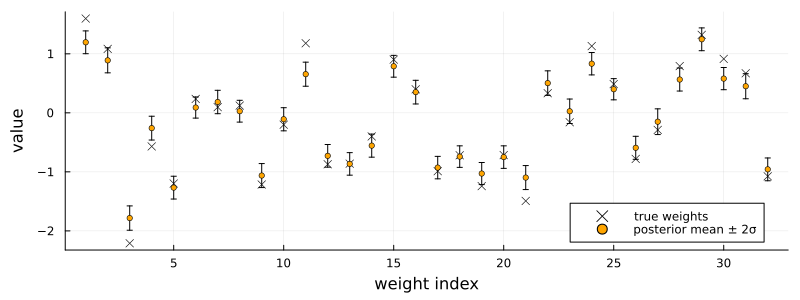

In [26]:
scatter(regression.θ, label = "true weights", color = :black, markershape = :x, xlabel = "weight index", ylabel = "value", size = (800, 300))
scatter!(mean(qθ), yerror = 2 .* sqrt.(var(qθ)), label = "posterior mean ± 2σ", color = :orange, markersize = 3, bottom_margin = 5Plots.mm, left_margin = 5Plots.mm)

**Where the time goes.** The engine forms $q(\theta)$ as the product of the prior and the $n$ messages from the `softdot` nodes. Those messages are in natural parameters, a weighted mean and a precision, so $q(\theta)$ is stored that way too, and that one object goes to all $n$ nodes. Each node reads it twice, in the rule towards $x_i$ and in the rule towards $\gamma$, and each read needs the mean and covariance of $\theta$, which for a distribution stored by its precision $\Lambda_\theta$ means factorizing and inverting it. A rule sees only its arguments, so nothing is shared: an iteration performs $2n$ factorizations of the same matrix. The marginals of the inputs have the same shape, each read twice.

In [27]:
@btime cov($qθ);
@btime mean($qθ);

  13.583 μs (3 allocations: 8.08 KiB)
  3.469 μs (5 allocations: 8.39 KiB)


**The fix.** The user never holds $q(\theta)$, but a functional form constraint is applied to every marginal once the engine has formed it and before the nodes read it. Usually a constraint changes the family; this one keeps the family and the parameters exactly, and only stores the precision as a wrapper. `MvNormalWeightedMeanPrecision` accepts any `AbstractMatrix`; its `cov` calls `cholinv` on the precision and its `mean` calls `fastcholesky`, and both read the cache. The first node to ask pays for one factorization; the other $2n-1$ reads are lookups.

A constraint subtypes `ReactiveMP.AbstractFormConstraint` and defines when it applies (once, to the whole product), which product strategy it needs (the generic one, since the family is unchanged), and the conversion. The wrapper requires an exactly symmetric matrix, hence `Symmetric`.

In [28]:
struct CachedPrecisionForm <: ReactiveMP.AbstractFormConstraint end

ReactiveMP.default_form_check_strategy(::CachedPrecisionForm) = ReactiveMP.FormConstraintCheckLast()
ReactiveMP.default_prod_constraint(::CachedPrecisionForm) = BayesBase.GenericProd()

function ReactiveMP.constrain_form(::CachedPrecisionForm, q::MultivariateNormalDistributionsFamily)
    ξ, Λ = weightedmean_precision(q)
    return MvNormalWeightedMeanPrecision(ξ, MatrixWithCachedInverse(Symmetric(Λ)))
end

constraints_θ = @constraints begin
    q(θ, x, γ) = q(θ)q(x)q(γ)
    q(θ) :: CachedPrecisionForm()
end

constraints_θx = @constraints begin
    q(θ, x, γ) = q(θ)q(x)q(γ)
    q(θ) :: CachedPrecisionForm()
    q(x) :: CachedPrecisionForm()
end

Constraints: 
  q(θ, x, γ) = q(θ)q(x)q(γ)
  q(θ) :: CachedPrecisionForm()
  q(x) :: CachedPrecisionForm()


The posteriors are the same to rounding, and the returned $q(\theta)$ carries the wrapper with the caches the rules filled, so reading it afterwards is free too:

In [29]:
result_cached = regress(regression, constraints_θx)
qθ_cached = result_cached.posteriors[:θ]

largest_difference = max(
    maximum(abs, mean(qθ) - mean(qθ_cached)),
    maximum(abs, cov(qθ) - cov(qθ_cached)),
    maximum(maximum(abs, mean(a) - mean(b)) for (a, b) in zip(result.posteriors[:x], result_cached.posteriors[:x])),
)
@assert largest_difference < 1e-8 # hide
println("largest difference between the two runs: ", largest_difference)
println("precision of q(θ) is stored as ", typeof(qθ_cached.Λ).name.name)
@btime cov($qθ_cached);
@btime mean($qθ_cached);

largest difference between the two runs: 2.220446049250313e-15
precision of q(θ) is stored as MatrixWithCachedInverse
  50.719 ns (0 allocations: 0 bytes)
  785.774 ns (2 allocations: 320 bytes)


In [30]:
input_counts = [16, 32, 64, 128]
regression_timings = map(input_counts) do d
    p = regression_problem(d, n)
    stock = @benchmark regress($p, $constraints) seconds = 2
    cached_θ = @benchmark regress($p, $constraints_θ) seconds = 2
    cached_θx = @benchmark regress($p, $constraints_θx) seconds = 2
    return (d = d, stock = median(stock).time / 1e6, θ = median(cached_θ).time / 1e6, θx = median(cached_θx).time / 1e6)
end

┌ Warning: JSON-RPC endpoint has been blocked writing to its peer; outgoing messages are queueing up and will not be delivered until the peer resumes reading
│   blocked_seconds = 76.4
│   queued_messages = 0
└ @ VSCodeServer.JSONRPC /Users/mykola/.vscode/extensions/julialang.language-julia-1.250.2/scripts/packages/JSONRPC/src/core.jl:414


4-element Vector{@NamedTuple{d::Int64, stock::Float64, θ::Float64, θx::Float64}}:
 (d = 16, stock = 62.805792, θ = 39.582167, θx = 40.6454795)
 (d = 32, stock = 183.088542, θ = 109.454125, θx = 82.527542)
 (d = 64, stock = 654.6819375, θ = 452.438584, θx = 349.503167)
 (d = 128, stock = 2520.453791, θ = 1621.133, θx = 1288.98325)

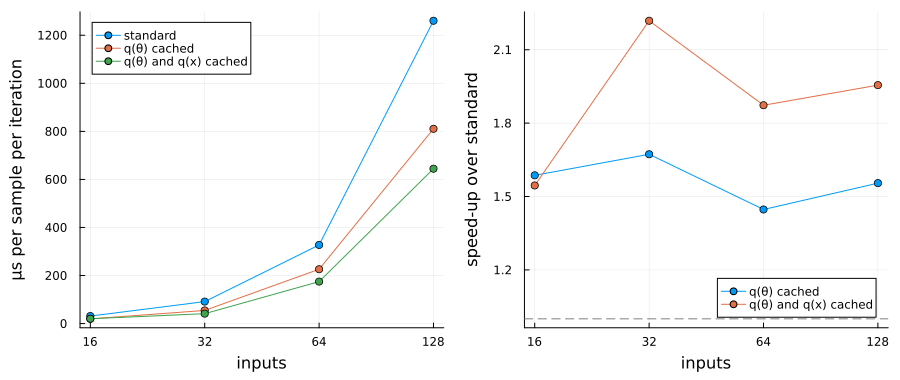

In [31]:
speedup = plot(input_counts, [t.stock / t.θ for t in regression_timings], marker = :circle, label = "q(θ) cached", xscale = :log2, xticks = (input_counts, string.(input_counts)), xlabel = "inputs", ylabel = "speed-up over standard", legend = :bottomright)
plot!(speedup, input_counts, [t.stock / t.θx for t in regression_timings], marker = :circle, label = "q(θ) and q(x) cached")
hline!(speedup, [1.0], linestyle = :dash, color = :gray, label = nothing)
per_sample = plot(input_counts, [t.stock / n * 1e3 / 10 for t in regression_timings], marker = :circle, label = "standard", xscale = :log2, xticks = (input_counts, string.(input_counts)), xlabel = "inputs", ylabel = "μs per sample per iteration", legend = :topleft)
plot!(per_sample, input_counts, [t.θ / n * 1e3 / 10 for t in regression_timings], marker = :circle, label = "q(θ) cached")
plot!(per_sample, input_counts, [t.θx / n * 1e3 / 10 for t in regression_timings], marker = :circle, label = "q(θ) and q(x) cached")
plot(per_sample, speedup, layout = (1, 2), size = (900, 380), left_margin = 5Plots.mm, bottom_margin = 5Plots.mm)

Caching $q(\theta)$ alone removes $2n-1$ of the $2n$ factorizations of $\Lambda_\theta$ per iteration and makes the run about one and a half times faster; caching the inputs as well turns the two reads of each $q(x_i)$ into one, and the run is about twice as fast. What remains is one factorization per marginal, the $O(d^2)$ products in the rules and the engine's per-node overhead, so the gain is flat in $d$ rather than growing.

Nothing here is specific to `softdot`. Any variational model with a parameter whose marginal is read by many nodes per iteration repeats the same factorization in every reader, and the same constraint removes it for any marginal in the multivariate normal family.

## Where it does not help

The cache answers requests for a factor or an inverse of a matrix the user placed. Three cases outside that:

- **Small matrices.** The engine's per-node work hides anything below a few tens of microseconds. A precision-form state-space model with $d \le 8$ states inverts its $d \times d$ process precision at every step and gains nothing measurable from caching it.
- **Matrices the rules build and discard.** A product like $B^\top R^{-1} B$ computed inside a rule is a fresh `Matrix` each time; the cache lives only in the object it wraps.

## Summary

`MatrixWithCachedInverse` makes a symmetric positive-definite matrix remember its factorization and inverse. Placed on a constant the model takes, it turns a factorization per node into one per run: a dense sensor-noise covariance in a wide-sensor smoother runs two to three times faster at a few hundred sensors. Placed inside a shared posterior through a form constraint that keeps the family and only changes the storage of the precision, it turns a factorization per reader into one per iteration: a `softdot` regression with cached weights and inputs runs about twice as fast. In both cases the model, the rules and the `infer` call are unchanged and the results are identical.